# 03 XGBoost: receiver risk model + reasons

Work card 03. Training runs as a background script in the **Jupyter terminal** (a few minutes on 3 CPUs):

```bash
cd ~/shared/trustpause
nohup python -m src.train_xgb > data/train_xgb.log 2>&1 &
tail -f data/train_xgb.log
```

Wait for `Saved .../xgb.json`, then run the cells below. Don't run other heavy jobs on the server meanwhile.

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import precision_recall_curve

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.features import FEATURE_NAMES
from src.reasons import reasons_for

metrics = json.loads((ROOT / 'models' / 'metrics.json').read_text())
thresholds = json.loads((ROOT / 'models' / 'thresholds.json').read_text())
print(f"Best iteration {metrics['best_iteration']}, trained in {metrics['train_seconds']} s")
print(f"Single prediction latency: p50 {metrics['single_predict_ms_p50']} ms, p95 {metrics['single_predict_ms_p95']} ms")
print(f"Thresholds: pause >= {thresholds['pause']:.4f}, hold >= {thresholds['hold']:.4f}")

Best iteration 283, trained in 73.9 s
Single prediction latency: p50 0.099 ms, p95 0.298 ms
Thresholds: pause >= 0.9283, hold >= 0.9894


## Headline metrics

Fraud is ~0.1% of transfers, so PR-AUC and precision/recall matter, not accuracy. Thresholds were chosen on **validation**; test is reported untouched.

In [2]:
rows = []
for split in ('val', 'test'):
    m = metrics[split]
    for name in ('pause_band', 'hold_band'):
        rows.append({'split': split, 'band': name.replace('_band', ''), 'pr_auc': m['pr_auc'], 'roc_auc': m['roc_auc'], **m[name]})
pd.DataFrame(rows)

,split,band,pr_auc,roc_auc,threshold,alert_rate_%,alerts,laundering_caught,precision_%,recall_%
0,val,pause,0.3608,0.9823,0.928334,0.5000,4828,642,13.30,61.97
1,val,hold,0.3608,0.9823,0.989390,0.0500,483,299,61.90,28.86
2,test,pause,0.2541,0.9738,0.928334,0.6958,6003,496,8.26,51.88
3,test,hold,0.2541,0.9738,0.989390,0.0487,420,219,52.14,22.91


## Precision / recall at different alert budgets

`alert_rate_%` = share of all transfers flagged. Use this to choose the pause and hold budgets (`--pause-rate`, `--hold-rate`).

In [3]:
for split in ('val', 'test'):
    print(split)
    display(pd.DataFrame(metrics[split]['by_alert_rate']))

val


,threshold,alert_rate_%,alerts,laundering_caught,precision_%,recall_%
0,0.996038,0.0201,194,159,81.96,15.35
1,0.989390,0.0500,483,299,61.90,28.86
2,0.982663,0.1000,966,387,40.06,37.36
3,0.970526,0.2001,1932,483,25.00,46.62
4,0.928334,0.5000,4828,642,13.30,61.97
5,0.801914,1.0001,9656,767,7.94,74.03
6,0.490184,2.0001,19311,844,4.37,81.47


test


,threshold,alert_rate_%,alerts,laundering_caught,precision_%,recall_%
0,0.996038,0.0152,131,95,72.52,9.94
1,0.989390,0.0487,420,219,52.14,22.91
2,0.982663,0.1008,870,281,32.30,29.39
3,0.970526,0.2258,1948,370,18.99,38.70
4,0.928334,0.6958,6003,496,8.26,51.88
5,0.801914,1.8423,15895,641,4.03,67.05
6,0.490184,3.6535,31522,762,2.42,79.71


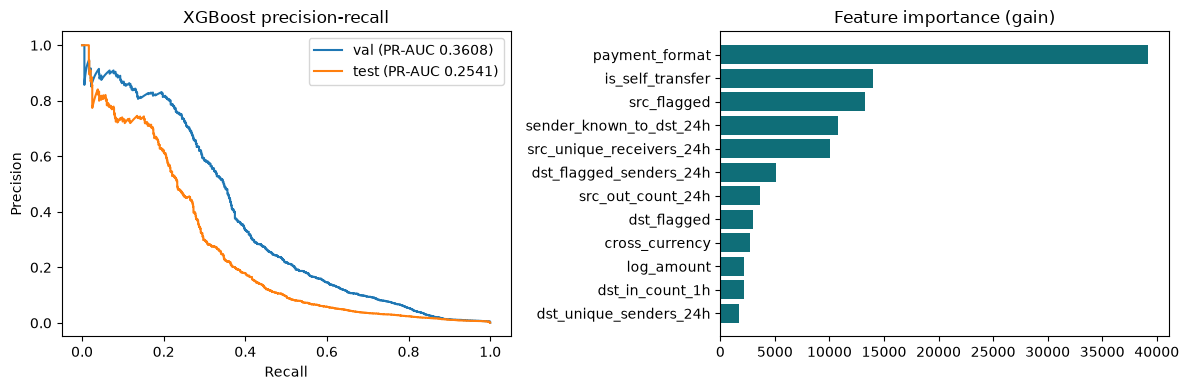

In [4]:
import matplotlib.pyplot as plt

scores = pd.read_pickle(ROOT / 'data' / 'xgb_scores.pkl')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for split in ('val', 'test'):
    s = scores[scores['split'] == split]
    p, r, _ = precision_recall_curve(s['label'], s['score_xgb'])
    axes[0].plot(r, p, label=f"{split} (PR-AUC {metrics[split]['pr_auc']})")
axes[0].set_xlabel('Recall'); axes[0].set_ylabel('Precision'); axes[0].set_title('XGBoost precision-recall'); axes[0].legend()

imp = pd.Series(metrics['importance_gain']).head(12)[::-1]
axes[1].barh(imp.index, imp.values, color='#0F6E78'); axes[1].set_title('Feature importance (gain)')
plt.tight_layout()
plt.savefig(ROOT / 'screenshots' / 'xgb_pr_and_importance.png', dpi=150)
plt.show()

## Reload check and example explanations

Reasons come from XGBoost's own `pred_contribs` (SHAP values), so no `shap` package is needed. Sentences contain counts and amounts only, never account IDs.

In [5]:
booster = xgb.Booster()
booster.load_model(ROOT / 'models' / 'xgb.json')

features = pd.read_pickle(ROOT / 'data' / 'features_all.pkl')
test = features[features['split'] == 'test']
del features

saved = scores.loc[test.index[:1000], 'score_xgb'].to_numpy()
again = booster.inplace_predict(test[FEATURE_NAMES].iloc[:1000].to_numpy(dtype=np.float32))
print('Reloaded model gives the same scores:', np.allclose(saved, again, atol=1e-6))

Reloaded model gives the same scores: True


In [6]:
def decision(score):
    return 'HOLD' if score >= thresholds['hold'] else 'PAUSE' if score >= thresholds['pause'] else 'ALLOW'

test_scores = scores[scores['split'] == 'test']
examples = pd.concat([
    test_scores[test_scores['label'] == 1].nlargest(3, 'score_xgb'),
    test_scores[test_scores['label'] == 1].sample(1, random_state=0),
    test_scores[test_scores['label'] == 0].nlargest(1, 'score_xgb'),
])
X_examples = test.loc[examples.index, FEATURE_NAMES]
for_analyst = reasons_for(booster, X_examples, FEATURE_NAMES, audience='analyst')
for_sender = reasons_for(booster, X_examples, FEATURE_NAMES, audience='sender')
for (idx, row), analyst, sender in zip(examples.iterrows(), for_analyst, for_sender):
    kind = 'laundering' if row['label'] else 'normal'
    print(f"score {row['score_xgb']:.4f} -> {decision(row['score_xgb'])}  (actually {kind})")
    print('  analyst view:')
    for r in analyst:
        print(f"    [{r['code']}] {r['sentence']}")
    print('  sender view:')
    for r in sender:
        print(f"    [{r['code']}] {r['sentence']}")
    print()

score 0.9996 -> HOLD  (actually laundering)
  analyst view:
    [RECEIVER_REPORTED] the receiving account is linked to an earlier reported case
    [SENDER_REPORTED] the sending account is linked to an earlier reported case
    [FAN_IN_HIGH] the receiving account got money from 4 different senders in the last 24 hours
  sender view:
    [RECEIVER_REPORTED] the receiving account is linked to an earlier reported case
    [FAN_IN_HIGH] the receiving account got money from 4 different senders in the last 24 hours
    [RECEIVER_VOLUME] the receiving account received 9 transfers in the last 24 hours

score 0.9995 -> HOLD  (actually laundering)
  analyst view:
    [RECEIVER_REPORTED] the receiving account is linked to an earlier reported case
    [SENDER_REPORTED] the sending account is linked to an earlier reported case
    [FAN_IN_HIGH] the receiving account got money from 4 different senders in the last 24 hours
  sender view:
    [RECEIVER_REPORTED] the receiving account is linked to an e